In [1]:
import os
import sys
from pathlib import Path
import zipfile
import re
import pandas as pd

# 1. Configurar caminhos e variáveis (agora COM a VD3004)
PASTA = Path.cwd()
DIC = PASTA / 'Dicionario_e_input_20221031.zip'
ARQUIVOS = [PASTA / 'PNADC_012024_20250815.zip', PASTA / 'PNADC_022024_20260324.zip']

VARIAVEIS = [
    'Ano', 'Trimestre', 'UF', 'UPA', 'Estrato', 'V1008', 'V1014', 'V1016', 'V1028',
    'V2003', 'V2007', 'V2008', 'V20081', 'V20082', 'V2009', 'V4012', 'V4019',
    'V4046', 'VD3004', 'VD4001', 'VD4002', 'VD4009' 
]

# 2. Ler o dicionário no arquivo SAS
print("Lendo o dicionário SAS e mapeando posições...")
with zipfile.ZipFile(DIC) as z:
    sas = z.read('input_PNADC_trimestral.sas').decode('latin-1')

positions = {}
for line in sas.splitlines():
    match = re.match(r'\s*@0*(\d+)\s+(\w+)\s+\$?(\d+)\.', line)
    if match:
        start, name, width = match.groups()
        positions[name] = (int(start) - 1, int(start) - 1 + int(width))

# 3. Recriar os arquivos .parquet (sobrescrevendo os antigos)
print("Extraindo microdados originais e gerando novos arquivos Parquet (Aguarde)...")
for path in ARQUIVOS:
    records = []
    with zipfile.ZipFile(path) as z:
        txt = next(n for n in z.namelist() if n.lower().endswith('.txt'))
        with z.open(txt) as fh:
            for line in fh:
                records.append({
                    v: line[a:b].decode('ascii', errors='replace').strip() or None
                    for v in VARIAVEIS for a, b in [positions[v]]
                })
    df = pd.DataFrame.from_records(records)
    output = PASTA / (path.stem[:12] + '_selecionado.parquet')
    df.to_parquet(output, index=False)
    print(f" -> Arquivo {output.name} salvo com sucesso!")

# 4. Carregar os dados atualizados para o DataFrame do seu projeto
print("\nCarregando os novos dados para análise...")
df_tri1 = pd.read_parquet('PNADC_012024_selecionado.parquet')
df_tri2 = pd.read_parquet('PNADC_022024_selecionado.parquet')
df_pnad = pd.concat([df_tri1, df_tri2], ignore_index=True)

print(f"Pronto! Total de registros carregados: {len(df_pnad):,}")
display(df_pnad.head())

Lendo o dicionário SAS e mapeando posições...
Extraindo microdados originais e gerando novos arquivos Parquet (Aguarde)...
 -> Arquivo PNADC_012024_selecionado.parquet salvo com sucesso!
 -> Arquivo PNADC_022024_selecionado.parquet salvo com sucesso!

Carregando os novos dados para análise...
Pronto! Total de registros carregados: 961,335


,Ano,Trimestre,UF,UPA,Estrato,V1008,V1014,V1016,V1028,V2003,...,V20081,V20082,V2009,V4012,V4019,V4046,VD3004,VD4001,VD4002,VD4009
0,2024,1,11,110000016,1110011,03,11,1,000127.88030329,01,...,10,1954,069,None,None,None,2,2,None,None
1,2024,1,11,110000016,1110011,06,11,1,000205.91422143,01,...,07,1987,036,6,2,None,5,1,1,09
2,2024,1,11,110000016,1110011,06,11,1,000205.91422143,02,...,05,1984,039,None,None,None,5,2,None,None
3,2024,1,11,110000016,1110011,08,11,1,000236.99121623,01,...,06,1988,035,3,None,None,5,1,1,01
4,2024,1,11,110000016,1110011,08,11,1,000236.99121623,02,...,06,1995,028,None,None,None,5,2,None,None


In [2]:
import pandas as pd

# Carregar os microdados extraídos
df_tri1 = pd.read_parquet('PNADC_012024_selecionado.parquet')
df_tri2 = pd.read_parquet('PNADC_022024_selecionado.parquet')

# Unir o primeiro semestre num único DataFrame
df_pnad = pd.concat([df_tri1, df_tri2], ignore_index=True)

# Confirmar as dimensões e visualizar as primeiras linhas
print(f"Total de registos carregados: {len(df_pnad):,}")
display(df_pnad.head())

Total de registos carregados: 961,335


,Ano,Trimestre,UF,UPA,Estrato,V1008,V1014,V1016,V1028,V2003,...,V20081,V20082,V2009,V4012,V4019,V4046,VD3004,VD4001,VD4002,VD4009
0,2024,1,11,110000016,1110011,03,11,1,000127.88030329,01,...,10,1954,069,None,None,None,2,2,None,None
1,2024,1,11,110000016,1110011,06,11,1,000205.91422143,01,...,07,1987,036,6,2,None,5,1,1,09
2,2024,1,11,110000016,1110011,06,11,1,000205.91422143,02,...,05,1984,039,None,None,None,5,2,None,None
3,2024,1,11,110000016,1110011,08,11,1,000236.99121623,01,...,06,1988,035,3,None,None,5,1,1,01
4,2024,1,11,110000016,1110011,08,11,1,000236.99121623,02,...,06,1995,028,None,None,None,5,2,None,None


In [3]:
import pandas as pd

# 1. Renomeando as colunas conforme o Dicionário Oficial da PNAD Contínua
dicionario_nomes = {
    'V1008': 'Num_Selecao_Domicilio',
    'V1014': 'Painel',
    'V1016': 'Num_Entrevista',
    'V1028': 'Peso_Amostral',
    'V2003': 'Num_Ordem_Pessoa',
    'V2007': 'Sexo',
    'V2008': 'Dia_Nascimento',
    'V20081': 'Mes_Nascimento',
    'V20082': 'Ano_Nascimento',
    'V2009': 'Idade',
    'V4012': 'Posicao_Ocupacao_Trabalho',
    'V4019': 'Tem_CNPJ',
    'V4046': 'Tem_CNPJ_Adicional', 
    'VD3004': 'Escolaridade', # <--- A VARIÁVEL NOVA ADICIONADA AQUI
    'VD4001': 'Forca_de_Trabalho',
    'VD4002': 'Condicao_Ocupacao',
    'VD4009': 'Categoria_Emprego_Principal'
}

df_pnad = df_pnad.rename(columns=dicionario_nomes)

# 2. Criando as Chaves de Identificação conforme o arquivo Chaves_PNADC.pdf
# A chave de domicílio deve ser composta pelas variáveis: UPA + V1008 + V1014
df_pnad['Chave_Domicilio'] = (
    df_pnad['UPA'].astype(str) + 
    df_pnad['Num_Selecao_Domicilio'].astype(str) + 
    df_pnad['Painel'].astype(str)
)

# A chave de pessoas é composta pelas variáveis: UPA + V1008 + V1014 + V2003
df_pnad['Chave_Pessoa'] = (
    df_pnad['Chave_Domicilio'] + 
    df_pnad['Num_Ordem_Pessoa'].astype(str)
)

# Visualizando o resultado com as novas colunas, incluindo a Escolaridade
display(df_pnad[['Chave_Domicilio', 'Chave_Pessoa', 'Ano', 'Trimestre', 'Idade', 'Escolaridade', 'Forca_de_Trabalho']].head())

,Chave_Domicilio,Chave_Pessoa,Ano,Trimestre,Idade,Escolaridade,Forca_de_Trabalho
0,1100000160311,110000016031101,2024,1,069,2,2
1,1100000160611,110000016061101,2024,1,036,5,1
2,1100000160611,110000016061102,2024,1,039,5,2
3,1100000160811,110000016081101,2024,1,035,5,1
4,1100000160811,110000016081102,2024,1,028,5,2


In [4]:
# 1. Separar o DataFrame empilhado de volta nos trimestres específicos
df_t1 = df_pnad[df_pnad['Trimestre'] == '1'].copy()
df_t2 = df_pnad[df_pnad['Trimestre'] == '2'].copy()

# 2. Pareamento Longitudinal (Inner Join usando a Chave_Pessoa)
# O sufixo '_t1' será adicionado às colunas do 1º tri e '_t2' às do 2º tri
painel = pd.merge(
    df_t1, 
    df_t2, 
    on=['Chave_Domicilio', 'Chave_Pessoa', 'Num_Selecao_Domicilio', 'Painel'], 
    suffixes=('_t1', '_t2'), 
    how='inner'
)

# 3. Validar o pareamento (Consistência Demográfica)
# Converter idades para números (lidando com possíveis valores ausentes)
painel['Idade_t1'] = pd.to_numeric(painel['Idade_t1'], errors='coerce')
painel['Idade_t2'] = pd.to_numeric(painel['Idade_t2'], errors='coerce')

# Regra A: O sexo não pode mudar entre os trimestres
filtro_sexo = painel['Sexo_t1'] == painel['Sexo_t2']

# Regra B: A idade não pode diminuir, nem aumentar mais que 2 anos em um trimestre
diferenca_idade = painel['Idade_t2'] - painel['Idade_t1']
filtro_idade = (diferenca_idade >= 0) & (diferenca_idade <= 2)

# Aplicar os filtros para excluir pareamentos inconsistentes (Falsos Positivos)
painel_validado = painel[filtro_sexo & filtro_idade].copy()

# 4. Resultados do Pareamento
print(f"Total de registros originais no 1º Trimestre: {len(df_t1):,}")
print(f"Total de registros no Painel Inicial (Merged): {len(painel):,}")
print(f"Total de registros no Painel Validado: {len(painel_validado):,}")
print(f"Pareamentos descartados por inconsistência: {len(painel) - len(painel_validado):,}")

# Visualizar as colunas principais lado a lado
display(painel_validado[['Chave_Pessoa', 'Idade_t1', 'Idade_t2', 'Sexo_t1', 'Condicao_Ocupacao_t1', 'Condicao_Ocupacao_t2']].head())

Total de registros originais no 1º Trimestre: 481,349
Total de registros no Painel Inicial (Merged): 359,019
Total de registros no Painel Validado: 345,952
Pareamentos descartados por inconsistência: 13,067


,Chave_Pessoa,Idade_t1,Idade_t2,Sexo_t1,Condicao_Ocupacao_t1,Condicao_Ocupacao_t2
1,110000016061101,36,36,1,1,1
2,110000016061102,39,39,2,None,1
5,110000016091101,37,37,1,1,1
6,110000016091102,50,50,2,1,1
7,110000016101101,71,71,2,None,None


In [5]:
import numpy as np

# ---------------------------------------------------------
# ETAPA 3: Preparar a Amostra e Variável Dependente (Y)
# ---------------------------------------------------------

# 1. Remover da amostra quem JÁ ERA Conta Própria com CNPJ no 1º trimestre (t1)
# Códigos IBGE: VD4009 = '09' (Conta-própria) e V4019 = '1' (Sim, tem CNPJ)
filtro_ja_era_mei = (painel_validado['Categoria_Emprego_Principal_t1'] == '09') & (painel_validado['Tem_CNPJ_t1'] == '1')
amostra = painel_validado[~filtro_ja_era_mei].copy()

# 2. Criar Variável dependente: 1 se ingressou como Conta Própria com CNPJ em t2, 0 caso contrário
virou_mei = (amostra['Categoria_Emprego_Principal_t2'] == '09') & (amostra['Tem_CNPJ_t2'] == '1')
amostra['Ingresso_CNPJ'] = virou_mei.astype(int)

# ---------------------------------------------------------
# ETAPA 4: Construir a Variável Explicativa Principal (X)
# ---------------------------------------------------------

# Condições baseadas no Dicionário IBGE para o trimestre inicial (t1)
condicoes = [
    # 1. Empregado Formal: Com carteira ('01', '03', '05') ou Militar/Estatutário ('07')
    amostra['Categoria_Emprego_Principal_t1'].isin(['01', '03', '05', '07']),
    
    # 2. Empregado Informal: Sem carteira ('02', '04', '06')
    amostra['Categoria_Emprego_Principal_t1'].isin(['02', '04', '06']),
    
    # 3. Conta Própria Informal: Conta própria ('09') e Sem CNPJ ('2')
    (amostra['Categoria_Emprego_Principal_t1'] == '09') & (amostra['Tem_CNPJ_t1'] == '2'),
    
    # 4. Desempregado: Pessoas desocupadas (VD4002 == '2')
    amostra['Condicao_Ocupacao_t1'] == '2',
    
    # 5. Inativo: Fora da força de trabalho (VD4001 == '2')
    amostra['Forca_de_Trabalho_t1'] == '2'
]

# Rótulos para as categorias do seu projeto
categorias = [
    'Empregado formal', 
    'Empregado informal', 
    'Conta própria informal', 
    'Desempregado', 
    'Inativo'
]

# Aplicar classificação. Outras categorias minoritárias (ex: Empregador, Auxiliar Familiar) ficam como 'Outros'
amostra['Situacao_Anterior'] = np.select(condicoes, categorias, default='Outros')

# ---------------------------------------------------------
# ETAPA 6: Tabela de Transição (Análise Descritiva)
# ---------------------------------------------------------

# Gerar a tabela exata solicitada na Proposta do Trabalho
tabela_transicao = amostra.groupby('Situacao_Anterior')['Ingresso_CNPJ'].agg(
    Pessoas_Observadas='count',
    Ingressaram_MEI='sum'
)

# Calcular a taxa percentual de transição
tabela_transicao['Taxa_Ingresso (%)'] = (tabela_transicao['Ingressaram_MEI'] / tabela_transicao['Pessoas_Observadas'] * 100).round(2)

# Exibir os resultados
print(f"Dimensão da amostra limpa (novos potenciais MEIs): {len(amostra):,} indivíduos.")
display(tabela_transicao.sort_values(by='Taxa_Ingresso (%)', ascending=False))

Dimensão da amostra limpa (novos potenciais MEIs): 337,082 indivíduos.


,Pessoas_Observadas,Ingressaram_MEI,Taxa_Ingresso (%)
Situacao_Anterior,,,
Conta própria informal,33469,1930,5.77
Empregado informal,32999,548,1.66
Outros,71089,709,1.00
Desempregado,11755,68,0.58
Empregado formal,64488,249,0.39
Inativo,123282,362,0.29


In [6]:
import statsmodels.formula.api as smf

# 1. Limpar valores nulos da variável independente
# O statsmodels não roda se houver "nan" nas variáveis da fórmula
amostra_reg = amostra.dropna(subset=['Situacao_Anterior']).copy()

# 2. Definir a fórmula do Modelo 1
# A função C() transforma a variável em categórica.
# Treatment(reference='Empregado formal') força o 'Empregado formal' a ser o intercepto (beta 0).
formula_m1 = "Ingresso_CNPJ ~ C(Situacao_Anterior, Treatment(reference='Empregado formal'))"

# 3. Estimar o modelo com Erros-Padrão Robustos (HC1)
# O uso de cov_type='HC1' corrige a heterocedasticidade, padrão esperado no MPL
modelo_1 = smf.ols(formula_m1, data=amostra_reg).fit(cov_type='HC1')

# 4. Exibir a tabela de resultados da regressão
print(modelo_1.summary())

                            OLS Regression Results                            
Dep. Variable:          Ingresso_CNPJ   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     471.7
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:08:39   Log-Likelihood:             2.8052e+05
No. Observations:              337082   AIC:                        -5.610e+05
Df Residuals:                  337076   BIC:                        -5.610e+05
Df Model:                           5                                         
Covariance Type:                  HC1                                         
                                                                                              coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------

In [7]:
import numpy as np
import statsmodels.formula.api as smf
import pandas as pd

# 1. Carregar os dados que agora já possuem a Escolaridade (VD3004)
df_tri1 = pd.read_parquet('PNADC_012024_selecionado.parquet')
df_tri2 = pd.read_parquet('PNADC_022024_selecionado.parquet')
df_pnad = pd.concat([df_tri1, df_tri2], ignore_index=True)

# 2. Renomear as colunas (incluindo Escolaridade)
dicionario_nomes = {
    'V1008': 'Num_Selecao_Domicilio', 'V1014': 'Painel', 'V1016': 'Num_Entrevista',
    'V1028': 'Peso_Amostral', 'V2003': 'Num_Ordem_Pessoa', 'V2007': 'Sexo',
    'V2008': 'Dia_Nascimento', 'V2009': 'Idade', 'V4012': 'Posicao_Ocupacao_Trabalho', 
    'V4019': 'Tem_CNPJ', 'VD3004': 'Escolaridade', 'VD4001': 'Forca_de_Trabalho',
    'VD4002': 'Condicao_Ocupacao', 'VD4009': 'Categoria_Emprego_Principal'
}
df_pnad = df_pnad.rename(columns=dicionario_nomes)

# 3. Criar Chaves e Pareamento Longitudinal
df_pnad['Chave_Domicilio'] = df_pnad['UPA'].astype(str) + df_pnad['Num_Selecao_Domicilio'].astype(str) + df_pnad['Painel'].astype(str)
df_pnad['Chave_Pessoa'] = df_pnad['Chave_Domicilio'] + df_pnad['Num_Ordem_Pessoa'].astype(str)

df_t1 = df_pnad[df_pnad['Trimestre'] == '1'].copy()
df_t2 = df_pnad[df_pnad['Trimestre'] == '2'].copy()

painel = pd.merge(df_t1, df_t2, on=['Chave_Domicilio', 'Chave_Pessoa', 'Num_Selecao_Domicilio', 'Painel'], suffixes=('_t1', '_t2'), how='inner')
painel['Idade_t1'] = pd.to_numeric(painel['Idade_t1'], errors='coerce')
painel['Idade_t2'] = pd.to_numeric(painel['Idade_t2'], errors='coerce')

painel_validado = painel[(painel['Sexo_t1'] == painel['Sexo_t2']) & ((painel['Idade_t2'] - painel['Idade_t1']).between(0, 2))].copy()

# 4. Criar Variáveis do Modelo (Removendo quem já era MEI)
amostra = painel_validado[~((painel_validado['Categoria_Emprego_Principal_t1'] == '09') & (painel_validado['Tem_CNPJ_t1'] == '1'))].copy()
amostra['Ingresso_CNPJ'] = ((amostra['Categoria_Emprego_Principal_t2'] == '09') & (amostra['Tem_CNPJ_t2'] == '1')).astype(int)

condicoes = [
    amostra['Categoria_Emprego_Principal_t1'].isin(['01', '03', '05', '07']),
    amostra['Categoria_Emprego_Principal_t1'].isin(['02', '04', '06']),
    (amostra['Categoria_Emprego_Principal_t1'] == '09') & (amostra['Tem_CNPJ_t1'] == '2'),
    amostra['Condicao_Ocupacao_t1'] == '2',
    amostra['Forca_de_Trabalho_t1'] == '2'
]
amostra['Situacao_Anterior'] = np.select(condicoes, ['Empregado formal', 'Empregado informal', 'Conta própria informal', 'Desempregado', 'Inativo'], default='Outros')

# 5. Mapear Controles (Sexo, Idade, Região e Escolaridade)
amostra['Sexo'] = np.where(amostra['Sexo_t1'] == '1', 'Homem', 'Mulher')
amostra['Idade'] = amostra['Idade_t1']
amostra['Regiao'] = np.select([amostra['UF_t1'].astype(str).str[0] == str(i) for i in range(1, 6)], ['Norte', 'Nordeste', 'Sudeste', 'Sul', 'Centro-Oeste'], default='Desconhecida')

mapa_escolaridade = {
    '1': '1. Sem instrução', '2': '2. Fundamental incompleto', '3': '3. Fundamental completo',
    '4': '4. Médio incompleto', '5': '5. Médio completo', '6': '6. Superior incompleto', '7': '7. Superior completo'
}
amostra['Escolaridade'] = amostra['Escolaridade_t1'].map(mapa_escolaridade)

# 6. Rodar o Modelo 2 Completo
amostra_reg2 = amostra.dropna(subset=['Situacao_Anterior', 'Sexo', 'Idade', 'Regiao', 'Escolaridade']).copy()

formula_m2 = (
    "Ingresso_CNPJ ~ C(Situacao_Anterior, Treatment(reference='Empregado formal')) + "
    "Idade + C(Sexo, Treatment(reference='Homem')) + "
    "C(Regiao, Treatment(reference='Sudeste')) + "
    "C(Escolaridade, Treatment(reference='5. Médio completo'))"
)
modelo_2 = smf.ols(formula_m2, data=amostra_reg2).fit(cov_type='HC1')
print(modelo_2.summary())

                            OLS Regression Results                            
Dep. Variable:          Ingresso_CNPJ   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     190.1
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:08:52   Log-Likelihood:             2.5727e+05
No. Observations:              317757   AIC:                        -5.145e+05
Df Residuals:                  317739   BIC:                        -5.143e+05
Df Model:                          17                                         
Covariance Type:                  HC1                                         
                                                                                              coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------

In [8]:
import statsmodels.formula.api as smf
import pandas as pd

# ---------------------------------------------------------
# AJUSTE 3: Garantir a exata mesma amostra para ambos os modelos
# ---------------------------------------------------------
# Removemos NAs de todas as variáveis, incluindo o Peso Amostral
amostra_final = amostra.dropna(subset=[
    'Situacao_Anterior', 'Sexo', 'Idade', 'Regiao', 'Escolaridade', 'Peso_Amostral_t1', 'UPA_t1'
]).copy()

# Garantir que o peso e a UPA são numéricos para os cálculos
amostra_final['Peso_Amostral'] = pd.to_numeric(amostra_final['Peso_Amostral_t1'], errors='coerce')
amostra_final['UPA'] = amostra_final['UPA_t1'].astype(str)

print(f"Observações finais padronizadas para os dois modelos: {len(amostra_final):,}")

# ---------------------------------------------------------
# AJUSTE 2: Desenho Amostral (Pesos e Erros por Conglomerado)
# ---------------------------------------------------------

# MODELO 1 (WLS - Weighted Least Squares)
formula_m1 = "Ingresso_CNPJ ~ C(Situacao_Anterior, Treatment(reference='Empregado formal'))"

# Usa-se smf.wls (Weighted) em vez de ols, e ajusta-se a covariância para os clusters (UPA)
modelo_1_pesado = smf.wls(formula_m1, data=amostra_final, weights=amostra_final['Peso_Amostral']).fit(
    cov_type='cluster', cov_kwds={'groups': amostra_final['UPA']}
)

# MODELO 2 (WLS - Weighted Least Squares)
formula_m2 = (
    "Ingresso_CNPJ ~ C(Situacao_Anterior, Treatment(reference='Empregado formal')) + "
    "Idade + C(Sexo, Treatment(reference='Homem')) + "
    "C(Regiao, Treatment(reference='Sudeste')) + "
    "C(Escolaridade, Treatment(reference='5. Médio completo'))"
)

modelo_2_pesado = smf.wls(formula_m2, data=amostra_final, weights=amostra_final['Peso_Amostral']).fit(
    cov_type='cluster', cov_kwds={'groups': amostra_final['UPA']}
)

# Exibir os novos resultados robustos
print("\n" + "="*80)
print(" MODELO 1 (Com Pesos Amostrais, Erros de Conglomerado e Amostra Restrita)")
print("="*80)
print(modelo_1_pesado.summary())

print("\n" + "="*80)
print(" MODELO 2 (Com Pesos Amostrais, Erros de Conglomerado e Amostra Restrita)")
print("="*80)
print(modelo_2_pesado.summary())

Observações finais padronizadas para os dois modelos: 317,757

 MODELO 1 (Com Pesos Amostrais, Erros de Conglomerado e Amostra Restrita)
                            WLS Regression Results                            
Dep. Variable:          Ingresso_CNPJ   R-squared:                       0.026
Model:                            WLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     216.0
Date:                Fri, 20 Nov 2026   Prob (F-statistic):          2.26e-221
Time:                        11:09:02   Log-Likelihood:             1.7734e+05
No. Observations:              317757   AIC:                        -3.547e+05
Df Residuals:                  317751   BIC:                        -3.546e+05
Df Model:                           5                                         
Covariance Type:              cluster                                         
                                                                         

In [9]:
import plotly.graph_objects as go
import pandas as pd

# 1. Agrupar os dados usando os pesos amostrais para refletir a população real
transicoes = amostra_final.groupby(['Situacao_Anterior', 'Ingresso_CNPJ'])['Peso_Amostral'].sum().reset_index(name='Total_Pessoas')

# 2. Definir ordens e rótulos
origens = ['Conta própria informal', 'Empregado informal', 'Empregado formal', 'Desempregado', 'Inativo', 'Outros']
destinos = ['Continuou sem CNPJ', 'Ingressou no CNPJ (MEI)']
labels_nodes = origens + destinos

# Mapear índices
mapa_origens = {nome: i for i, nome in enumerate(origens)}
mapa_destinos = {0: len(origens), 1: len(origens) + 1}

source = transicoes['Situacao_Anterior'].map(mapa_origens).tolist()
target = transicoes['Ingresso_CNPJ'].map(mapa_destinos).tolist()
value = transicoes['Total_Pessoas'].tolist()

# 3. Criar uma paleta de cores harmoniosa para cada categoria de origem
cores_origem = {
    'Conta própria informal': '#e74c3c', # Vermelho/Laranja forte (destaque principal)
    'Empregado informal': '#e67e22',     # Laranja
    'Empregado formal': '#2980b9',       # Azul clássico
    'Desempregado': '#8e44ad',           # Roxo
    'Inativo': '#7f8c8d',                # Cinza
    'Outros': '#16a085'                  # Verde água
}

# Atribuir cores aos nós da esquerda e repassar transparência para os links
node_colors = [cores_origem.get(orig, '#34495e') for orig in origens] + ['#bdc3c7', '#27ae60']

link_colors = []
for src in source:
    nome_origem = origens[src]
    cor_hex = cores_origem.get(nome_origem, '#95a5a6')
    # Converter hex para rgba com transparência elegante
    h = cor_hex.lstrip('#')
    rgb = tuple(int(h[i:i+2], 16) for i in (0, 2, 4))
    link_colors.append(f"rgba({rgb[0]}, {rgb[1]}, {rgb[2]}, 0.45)")

# 4. Construir o Diagrama de Sankey aprimorado
fig = go.Figure(data=[go.Sankey(
    arrangement = "perpendicular",
    node = dict(
      pad = 20,
      thickness = 25,
      line = dict(color = "white", width = 1),
      label = labels_nodes,
      color = node_colors
    ),
    link = dict(
      source = source,
      target = target,
      value = value,
      color = link_colors
  ))])

# 5. Layout profissional limpo
fig.update_layout(
    title_text="<b>Dinâmica de Transição para o MEI no Brasil</b><br><sup>Passagem da situação ocupacional inicial para a formalização (1º ao 2º Trimestre de 2024)</sup>",
    font=dict(size=13, family="Arial, sans-serif"),
    plot_bgcolor='white',
    paper_bgcolor='white',
    height=650,
    margin=dict(t=80, b=50, l=50, r=50)
)

fig.show()

C:\Users\leona\AppData\Local\Temp\ipykernel_1292\1144130509.py:7: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



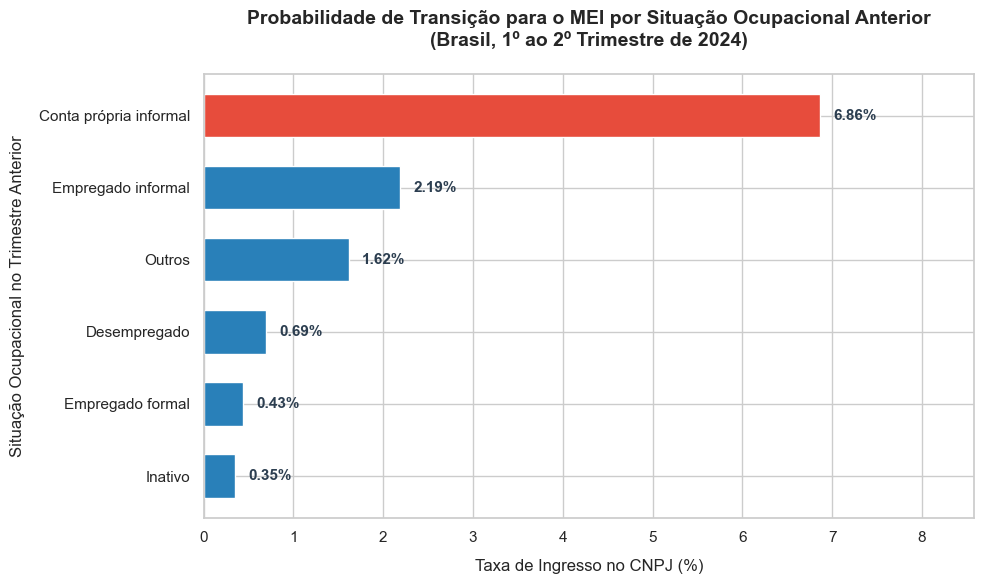

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Calcular as taxas de transição reais ponderadas por grupo
# Agrupamos por situação anterior e somamos o total de pessoas e os que viraram MEI
df_taxas = amostra_final.groupby('Situacao_Anterior').apply(
    lambda x: pd.Series({
        'Taxa_Ingresso': (x.loc[x['Ingresso_CNPJ'] == 1, 'Peso_Amostral'].sum() / x['Peso_Amostral'].sum()) * 100
    })
).reset_index()

# 2. Ordenar da maior para a menor taxa para dar um aspeto limpo e profissional
df_taxas = df_taxas.sort_values(by='Taxa_Ingresso', ascending=True)

# 3. Construir o Gráfico de Barras Horizontais
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Criar as barras com uma cor de destaque profissional (azul escuro/petróleo)
paleta = ['#2980b9' if cat != 'Conta própria informal' else '#e74c3c' for cat in df_taxas['Situacao_Anterior']]
barras = plt.barh(df_taxas['Situacao_Anterior'], df_taxas['Taxa_Ingresso'], color=paleta, height=0.6)

# 4. Adicionar os valores exatos (rótulos de dados) ao lado de cada barra
for barra in barras:
    largura = barra.get_width()
    plt.text(
        largura + 0.15, barra.get_y() + barra.get_height()/2, 
        f'{largura:.2f}%', 
        va='center', ha='left', fontsize=11, fontweight='bold', color='#2c3e50'
    )

# 5. Estilização e Títulos (Padrão Académico)
plt.title('Probabilidade de Transição para o MEI por Situação Ocupacional Anterior\n(Brasil, 1º ao 2º Trimestre de 2024)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Taxa de Ingresso no CNPJ (%)', fontsize=12, labelpad=10)
plt.ylabel('Situação Ocupacional no Trimestre Anterior', fontsize=12, labelpad=10)

# Ajustar limites do eixo X para dar espaço aos números impressos
plt.xlim(0, df_taxas['Taxa_Ingresso'].max() * 1.25)

plt.tight_layout()
plt.show()